In [49]:
# ============================================================
# Read sample sheets, find annotated CNR files,
# match samples, and print summary
# ============================================================

import os
import re
import glob
import pandas as pd

# -----------------------------
# Paths
# -----------------------------
NST_DIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNVKit/Annotated_cnr_file"
ILC_DIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/CNVKit/Annotated_cnr_file"

SAMPLE_SHEETS = [
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/EnRich/Sample_Sheet/sample_sheet_021326.csv",
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/EnRich/Sample_Sheet/sample_sheet_012425.csv",
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/EnRich/Sample_Sheet/sample_sheet_010526.csv",
]

# -----------------------------
# Helpers
# -----------------------------
def normalize_sample(x):
    """Make sample names comparable: TP23_M487 == TP23-M487"""
    if pd.isna(x):
        return ""
    return re.sub(r"[^A-Za-z0-9]", "", str(x)).lower()

def read_sample_list(sheet_paths):
    """Read unique sample names from all sample sheets."""
    samples = []
    seen = set()

    for fp in sheet_paths:
        df = pd.read_csv(fp)
        if "Sample" not in df.columns:
            raise ValueError(f"'Sample' column not found in {fp}")

        for s in df["Sample"].dropna().astype(str):
            s = s.strip()
            if s and s not in seen:
                seen.add(s)
                samples.append(s)

    return samples

def discover_cnr_files(root_dir, subtype):
    """Find all *.annotated.cnr files and store basic matching info."""
    files = []
    found = set()

    patterns = [
        os.path.join(root_dir, "**", "*.annotated.cnr"),
        os.path.join(root_dir, "*.annotated.cnr"),
    ]

    for pat in patterns:
        for fp in glob.glob(pat, recursive=True):
            if fp in found:
                continue
            found.add(fp)

            base = os.path.basename(fp)
            stem = re.sub(r"\.annotated\.cnr$", "", base, flags=re.IGNORECASE)
            parent = os.path.basename(os.path.dirname(fp))

            files.append({
                "path": fp,
                "subtype": subtype,
                "base": base,
                "stem": stem,
                "parent": parent,
                "norm_stem": normalize_sample(stem),
                "norm_parent": normalize_sample(parent),
            })

    return files

def index_files(files):
    """Create lookup dictionaries."""
    stem_index = {}
    parent_index = {}

    for rec in files:
        stem_index.setdefault(rec["norm_stem"], []).append(rec)
        parent_index.setdefault(rec["norm_parent"], []).append(rec)

    return stem_index, parent_index

def match_sample_to_file(sample, stem_index, parent_index):
    """Match one sample to one annotated CNR file."""
    key = normalize_sample(sample)

    candidates = []
    if key in stem_index:
        candidates.extend(stem_index[key])
    if key in parent_index:
        candidates.extend(parent_index[key])

    # remove duplicate paths
    uniq = {}
    for c in candidates:
        uniq[c["path"]] = c
    candidates = list(uniq.values())

    if len(candidates) == 0:
        return None

    if len(candidates) == 1:
        return candidates[0]

    # prefer exact stem match
    exact_stem = [c for c in candidates if c["norm_stem"] == key]
    if len(exact_stem) == 1:
        return exact_stem[0]

    # reproducible fallback
    candidates = sorted(candidates, key=lambda x: x["path"])
    return candidates[0]

# -----------------------------
# Read sample sheets
# -----------------------------
all_samples = read_sample_list(SAMPLE_SHEETS)
selected_samples = all_samples[:]   # all 64 samples

print(f"[INFO] Total unique samples from sheets: {len(all_samples)}")
print(f"[INFO] Samples to process: {len(selected_samples)}")

# -----------------------------
# Find annotated CNR files
# -----------------------------
nst_files = discover_cnr_files(NST_DIR, "NST")
ilc_files = discover_cnr_files(ILC_DIR, "ILC")
all_cnr_files = nst_files + ilc_files

print(f"[INFO] Found NST annotated cnr files: {len(nst_files)}")
print(f"[INFO] Found ILC annotated cnr files: {len(ilc_files)}")

# -----------------------------
# Match samples to files
# -----------------------------
stem_index, parent_index = index_files(all_cnr_files)

match_records = []
missing_samples = []

for sample in selected_samples:
    rec = match_sample_to_file(sample, stem_index, parent_index)
    if rec is None:
        missing_samples.append(sample)
    else:
        match_records.append({
            "Sample": sample,
            "Subtype": rec["subtype"],
            "CNR_File": rec["path"]
        })

match_df = pd.DataFrame(match_records)

print(f"[INFO] Matched samples: {len(match_df)}")
print(f"[INFO] Missing samples: {len(missing_samples)}")

if missing_samples:
    print("[INFO] Missing sample names:")
    for s in missing_samples:
        print(f"   - {s}")
else:
    print("[INFO] No missing sample names.")

[INFO] Total unique samples from sheets: 64
[INFO] Samples to process: 64
[INFO] Found NST annotated cnr files: 262
[INFO] Found ILC annotated cnr files: 112
[INFO] Matched samples: 21
[INFO] Missing samples: 43
[INFO] Missing sample names:
   - TP20_M220
   - TP20_M388
   - TP21_M100
   - TP21_M131
   - TP21_M136
   - TP21_M204
   - TP21_M312
   - TP21_M686
   - TP21_M825
   - TP22_M102
   - TP22_M128
   - TP22_M150
   - TP22_M517
   - TP23_M49
   - TP23_M80
   - TP23_M84
   - TP23_M132
   - TP23_M231
   - TP23_M242
   - TP23_M396
   - TP23_M462
   - TP23_M604
   - TP23_M605
   - TP24_M46
   - TP24_M67
   - TP24_M69
   - TP24_M166
   - TP24_M195
   - TP24_M229
   - TP24_M257_2
   - TP20_M63
   - TP21_M362
   - TP22_M34
   - TP22_M617
   - TP23_M531
   - TP23_M200
   - TP21_M557
   - TP23_M62
   - TP21_M828
   - TP24_M124
   - TP24_M292
   - TP24_M36
   - TP20_M80


In [50]:
# ============================================================
# Inspect Corrected_Call columns and collect all
# unique CNV call types across matched samples
# use *.Corrected_Call if present in that row
# otherwise use *.event
# otherwise use *.copy.number converted to call state
# ============================================================

import re
import numpy as np
import pandas as pd
from collections import Counter

def normalize_sample(x):
    if pd.isna(x):
        return ""
    return re.sub(r"[^A-Za-z0-9]", "", str(x)).lower()

def find_sample_column(df, sample_name, suffix):
    sample_key = normalize_sample(sample_name)
    matches = []

    for col in df.columns:
        if col.endswith(suffix):
            prefix = col[:-len(suffix)]
            if normalize_sample(prefix) == sample_key:
                matches.append(col)

    if len(matches) == 1:
        return matches[0]
    elif len(matches) > 1:
        return sorted(matches)[0]
    return None

def clean_series(s):
    s = s.astype(object)
    s = s.where(s.notna(), np.nan)
    s = s.astype(str).str.strip().replace({"": np.nan, "nan": np.nan, "None": np.nan})
    return s

def copy_number_to_call(x):
    if pd.isna(x):
        return np.nan
    try:
        x = float(x)
    except Exception:
        return np.nan

    if x <= 0:
        return "HOMD"
    elif x < 2:
        return "HETD"
    elif x == 2:
        return "NEUT"
    elif x < 4:
        return "GAIN"
    elif x < 8:
        return "AMP"
    else:
        return "HLAMP"

def get_rowwise_final_call(df, sample):
    corrected_col = find_sample_column(df, sample, ".Corrected_Call")
    event_col = find_sample_column(df, sample, ".event")
    copy_col = find_sample_column(df, sample, ".copy.number")

    corrected = pd.Series(np.nan, index=df.index, dtype=object)
    event = pd.Series(np.nan, index=df.index, dtype=object)
    copy_call = pd.Series(np.nan, index=df.index, dtype=object)

    if corrected_col is not None:
        corrected = clean_series(df[corrected_col])

    if event_col is not None:
        event = clean_series(df[event_col])

    if copy_col is not None:
        copy_call = df[copy_col].apply(copy_number_to_call)

    final_call = corrected.combine_first(event).combine_first(copy_call)
    return final_call

# -----------------------------
# Scan matched files
# -----------------------------
all_call_types = set()
call_type_counter = Counter()
sample_to_callcol = {}
samples_missing_callcol = []

print("[INFO] Checking Corrected_Call columns in matched files...\n")

for _, row in match_df.iterrows():
    sample = row["Sample"]
    cnr_file = row["CNR_File"]

    try:
        df = pd.read_csv(cnr_file, sep="\t", low_memory=False)

        final_call = get_rowwise_final_call(df, sample)
        usable = final_call.dropna()

        if len(usable) == 0:
            samples_missing_callcol.append(sample)
            continue

        sample_to_callcol[sample] = "rowwise_fallback"

        uniq = sorted(usable.unique())
        all_call_types.update(uniq)

        for v in usable:
            call_type_counter[v] += 1

    except Exception:
        samples_missing_callcol.append(sample)

# -----------------------------
# Print summary
# -----------------------------
print("\n[INFO] Samples with usable Corrected_Call column:", len(sample_to_callcol))
print("[INFO] Samples missing Corrected_Call column:", len(samples_missing_callcol))

if samples_missing_callcol:
    print("[INFO] Samples missing Corrected_Call column:")
    for s in samples_missing_callcol:
        print(f"   - {s}")

print("\n[INFO] Unique Corrected_Call states found:")
for x in sorted(all_call_types):
    print(f"   - {x}")

print("\n[INFO] Total counts of each Corrected_Call state across all matched files:")
for k, v in sorted(call_type_counter.items()):
    print(f"   {k}: {v}")

[INFO] Checking Corrected_Call columns in matched files...


[INFO] Samples with usable Corrected_Call column: 21
[INFO] Samples missing Corrected_Call column: 0

[INFO] Unique Corrected_Call states found:
   - AMP
   - GAIN
   - HETD
   - HLAMP
   - HOMD
   - NEUT

[INFO] Total counts of each Corrected_Call state across all matched files:
   AMP: 1506
   GAIN: 9044
   HETD: 7218
   HLAMP: 1310
   HOMD: 3
   NEUT: 35540


In [51]:
# ============================================================
# Build call_matrix from matched samples using row-wise final call
# Collapse duplicated gene entries by strongest event:
# HLAMP > AMP > GAIN > NEUT > HETD > HOMD
# ============================================================

import re
import numpy as np
import pandas as pd

GENES = [
    "PIK3CA", "TP53", "ESR1", "ERBB2", "CDH1", "KRAS", "TEP1", "BRAF",
    "CCND1", "FGFR1", "NF1", "RB1", "ARID1A", "EGFR", "FGFR2", "SMAD4",
    "AKT1", "ATM", "CDK6", "MYC", "CCNE1", "RAF1", "RHOA", "BRCA1",
    "BRCA2", "GATA3", "IDH2", "MET", "TERT"
]
# PTEN = TEP1 (alias)
gene_set = set(GENES)
sample_order = list(match_df["Sample"])

CALL_PRIORITY = {
    "HLAMP": 5,
    "AMP": 4,
    "GAIN": 3,
    "NEUT": 2,
    "HETD": 1,
    "HOMD": 0
}

def split_genes(gene_value):
    if pd.isna(gene_value):
        return []
    return [x.strip() for x in re.split(r"[;,|]", str(gene_value)) if x.strip()]

def collapse_calls(call_list):
    valid = [c for c in call_list if c in CALL_PRIORITY]
    if not valid:
        return np.nan
    return sorted(valid, key=lambda x: CALL_PRIORITY[x], reverse=True)[0]

def normalize_sample(x):
    if pd.isna(x):
        return ""
    return re.sub(r"[^A-Za-z0-9]", "", str(x)).lower()

def find_sample_column(df, sample_name, suffix):
    sample_key = normalize_sample(sample_name)
    matches = []

    for col in df.columns:
        if col.endswith(suffix):
            prefix = col[:-len(suffix)]
            if normalize_sample(prefix) == sample_key:
                matches.append(col)

    if len(matches) == 1:
        return matches[0]
    elif len(matches) > 1:
        return sorted(matches)[0]
    return None

def clean_series(s):
    s = s.astype(object)
    s = s.where(s.notna(), np.nan)
    s = s.astype(str).str.strip().replace({"": np.nan, "nan": np.nan, "None": np.nan})
    return s

def copy_number_to_call(x):
    if pd.isna(x):
        return np.nan
    try:
        x = float(x)
    except Exception:
        return np.nan

    if x <= 0:
        return "HOMD"
    elif x < 2:
        return "HETD"
    elif x == 2:
        return "NEUT"
    elif x < 4:
        return "GAIN"
    elif x < 8:
        return "AMP"
    else:
        return "HLAMP"

def get_rowwise_final_call(df, sample):
    corrected_col = find_sample_column(df, sample, ".Corrected_Call")
    event_col = find_sample_column(df, sample, ".event")
    copy_col = find_sample_column(df, sample, ".copy.number")

    corrected = pd.Series(np.nan, index=df.index, dtype=object)
    event = pd.Series(np.nan, index=df.index, dtype=object)
    copy_call = pd.Series(np.nan, index=df.index, dtype=object)

    if corrected_col is not None:
        corrected = clean_series(df[corrected_col])

    if event_col is not None:
        event = clean_series(df[event_col])

    if copy_col is not None:
        copy_call = df[copy_col].apply(copy_number_to_call)

    final_call = corrected.combine_first(event).combine_first(copy_call)
    return final_call

call_matrix = pd.DataFrame(index=GENES, columns=sample_order, dtype=object)

for _, row in match_df.iterrows():
    sample = row["Sample"]
    cnr_file = row["CNR_File"]

    df = pd.read_csv(cnr_file, sep="\t", low_memory=False)

    final_call = get_rowwise_final_call(df, sample)

    gene_calls = {g: [] for g in GENES}

    tmp = pd.DataFrame({
        "gene": df["gene"],
        "final_call": final_call
    })

    for _, r in tmp.iterrows():
        gene_field = r["gene"]
        call_val = r["final_call"]

        if pd.isna(gene_field) or pd.isna(call_val):
            continue

        call_val = str(call_val).strip()
        if call_val == "":
            continue

        genes_here = split_genes(gene_field)
        matched_genes = [g for g in genes_here if g in gene_set]

        for g in matched_genes:
            gene_calls[g].append(call_val)

    for g in GENES:
        call_matrix.loc[g, sample] = collapse_calls(gene_calls[g])

print("[INFO] call_matrix shape:", call_matrix.shape)
display(call_matrix.iloc[:5, :5])

[INFO] call_matrix shape: (29, 21)


,TP19_M876,TP20_M486,TP21_M234,TP21_M504,TP21_M707
PIK3CA,NEUT,NEUT,NEUT,NEUT,NEUT
TP53,HETD,HETD,HETD,HETD,HETD
ESR1,NEUT,GAIN,NEUT,HETD,NEUT
ERBB2,HETD,NEUT,HETD,NEUT,HETD
CDH1,HETD,HETD,HETD,HETD,HETD


In [52]:
# ============================================================
# Convert call_matrix to numeric plot_matrix
# ============================================================

CALL_ORDER = ["HOMD", "HETD", "NEUT", "GAIN", "AMP", "HLAMP"]
CALL_TO_NUM = {c: i for i, c in enumerate(CALL_ORDER)}

CALL_COLORS = {
    "HOMD":  "#2166ac",
    "HETD":  "#67a9cf",
    "NEUT":  "#f7f7f7",
    "GAIN":  "#f4a582",
    "AMP":   "#d6604d",
    "HLAMP": "#b2182b",
}

SUBTYPE_COLORS = {
    "ILC": "#1f9e89",
    "NST": "#7b3294"
}

plot_matrix = call_matrix.replace(CALL_TO_NUM)

print("[INFO] plot_matrix shape:", plot_matrix.shape)
display(plot_matrix.iloc[:5, :5])

[INFO] plot_matrix shape: (29, 21)


,TP19_M876,TP20_M486,TP21_M234,TP21_M504,TP21_M707
PIK3CA,2,2,2,2,2
TP53,1,1,1,1,1
ESR1,2,3,2,1,2
ERBB2,1,2,1,2,1
CDH1,1,1,1,1,1


[INFO] plot_matrix shape: (29, 21)


/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


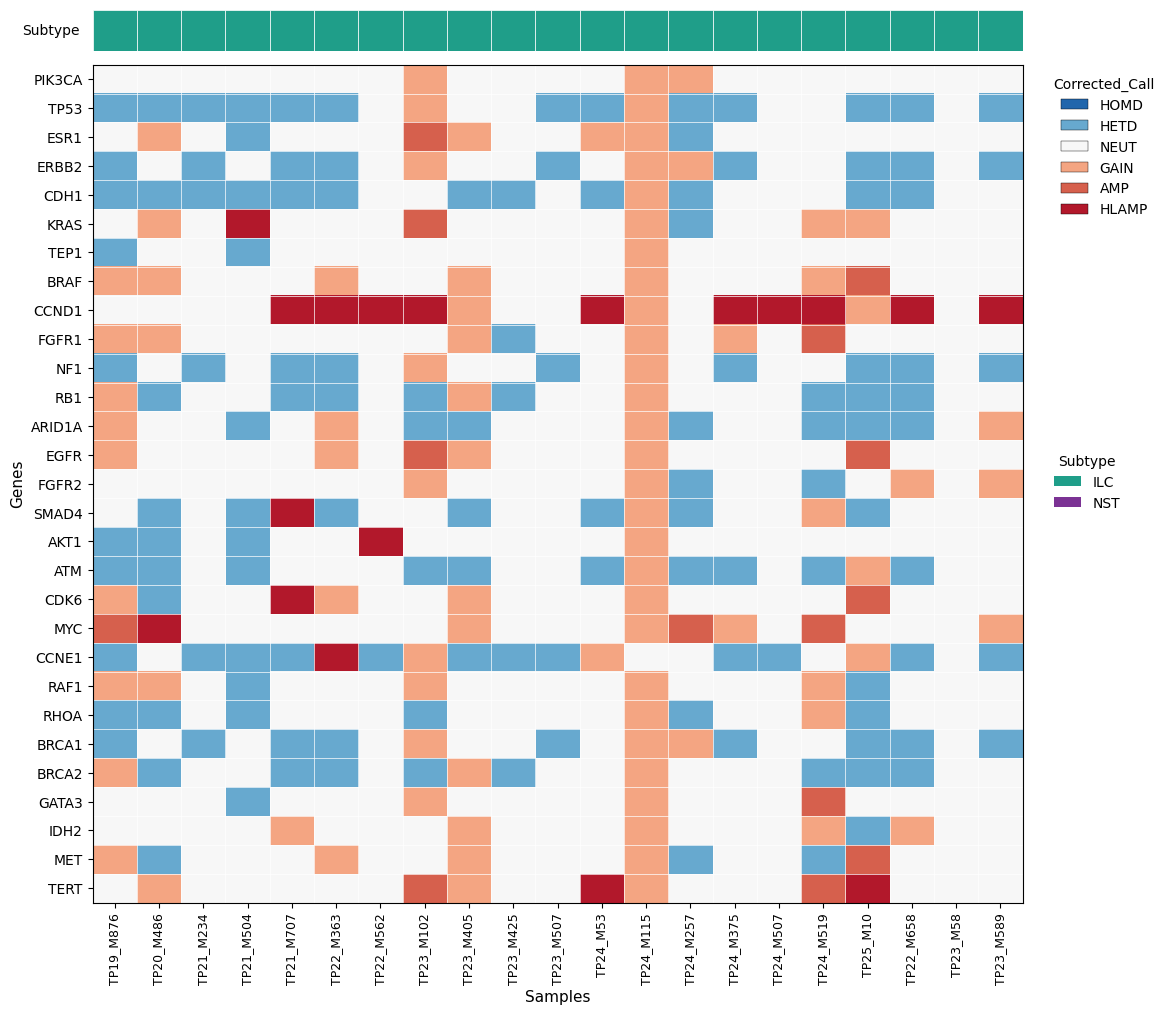

In [53]:
# ============================================================
# Plot categorical Corrected_Call heatmap
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.gridspec import GridSpec

# -----------------------------
# Define plotting order and colors
# -----------------------------
CALL_ORDER = ["HOMD", "HETD", "NEUT", "GAIN", "AMP", "HLAMP"]
CALL_TO_NUM = {c: i for i, c in enumerate(CALL_ORDER)}

CALL_COLORS = {
    "HOMD":  "#2166ac",
    "HETD":  "#67a9cf",
    "NEUT":  "#f7f7f7",
    "GAIN":  "#f4a582",
    "AMP":   "#d6604d",
    "HLAMP": "#b2182b",
}

SUBTYPE_COLORS = {
    "ILC": "#1f9e89",
    "NST": "#7b3294"
}

# -----------------------------
# Convert categorical matrix to numeric
# -----------------------------
plot_matrix = call_matrix.replace(CALL_TO_NUM)

print("[INFO] plot_matrix shape:", plot_matrix.shape)

# -----------------------------
# Figure size
# -----------------------------
n_genes = plot_matrix.shape[0]
n_samples = plot_matrix.shape[1]

fig_w = max(12, 0.45 * n_samples)
fig_h = max(8, 0.40 * n_genes)

fig = plt.figure(figsize=(fig_w, fig_h))
gs = GridSpec(nrows=2, ncols=1, height_ratios=[0.4, 8], hspace=0.03)

ax_top = fig.add_subplot(gs[0])
ax = fig.add_subplot(gs[1])

# -----------------------------
# Colormap
# -----------------------------
cmap = ListedColormap([CALL_COLORS[c] for c in CALL_ORDER])
norm = BoundaryNorm(np.arange(-0.5, len(CALL_ORDER) + 0.5, 1), cmap.N)

masked_values = np.ma.masked_invalid(plot_matrix.values.astype(float))
cmap = cmap.copy()
cmap.set_bad(color="lightgrey")

im = ax.imshow(masked_values, aspect="auto", cmap=cmap, norm=norm, interpolation="nearest")

# -----------------------------
# Axis labels
# -----------------------------
ax.set_xticks(np.arange(n_samples))
ax.set_xticklabels(plot_matrix.columns, rotation=90, fontsize=9)

ax.set_yticks(np.arange(n_genes))
ax.set_yticklabels(plot_matrix.index, fontsize=12)

ax.set_xlabel("Samples", fontsize=11)
ax.set_ylabel("Genes", fontsize=11)


# grid lines
ax.set_xticks(np.arange(-0.5, n_samples, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_genes, 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

# -----------------------------
# Top subtype annotation
# -----------------------------
subtype_map = dict(zip(match_df["Sample"], match_df["Subtype"]))

ax_top.set_xlim(-0.5, n_samples - 0.5)
ax_top.set_ylim(0, 1)

for i, sample in enumerate(plot_matrix.columns):
    subtype = subtype_map.get(sample, "Unknown")
    color = SUBTYPE_COLORS.get(subtype, "grey")
    rect = Rectangle((i - 0.5, 0), 1, 1, facecolor=color, edgecolor="white", linewidth=0.5)
    ax_top.add_patch(rect)

ax_top.set_xticks([])
ax_top.set_yticks([])
ax_top.set_frame_on(False)
ax_top.text(-0.8, 0.5, "Subtype", va="center", ha="right", fontsize=10)

# -----------------------------
# Legends
# -----------------------------
call_handles = [
    Patch(facecolor=CALL_COLORS[c], edgecolor="black", linewidth=0.3, label=c)
    for c in CALL_ORDER
]
subtype_handles = [
    Patch(facecolor=SUBTYPE_COLORS[s], edgecolor="none", label=s)
    for s in ["ILC", "NST"]
]

leg1 = ax.legend(
    handles=call_handles,
    title="Corrected_Call",
    bbox_to_anchor=(1.02, 1.00),
    loc="upper left",
    frameon=False
)
ax.add_artist(leg1)

ax.legend(
    handles=subtype_handles,
    title="Subtype",
    bbox_to_anchor=(1.02, 0.55),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()

[INFO] plot_matrix shape: (29, 21)
[INFO] Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/EnRich/CNV/selected_gene_CNV_heatmap.png
[INFO] Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/EnRich/CNV/selected_gene_CNV_heatmap.pdf


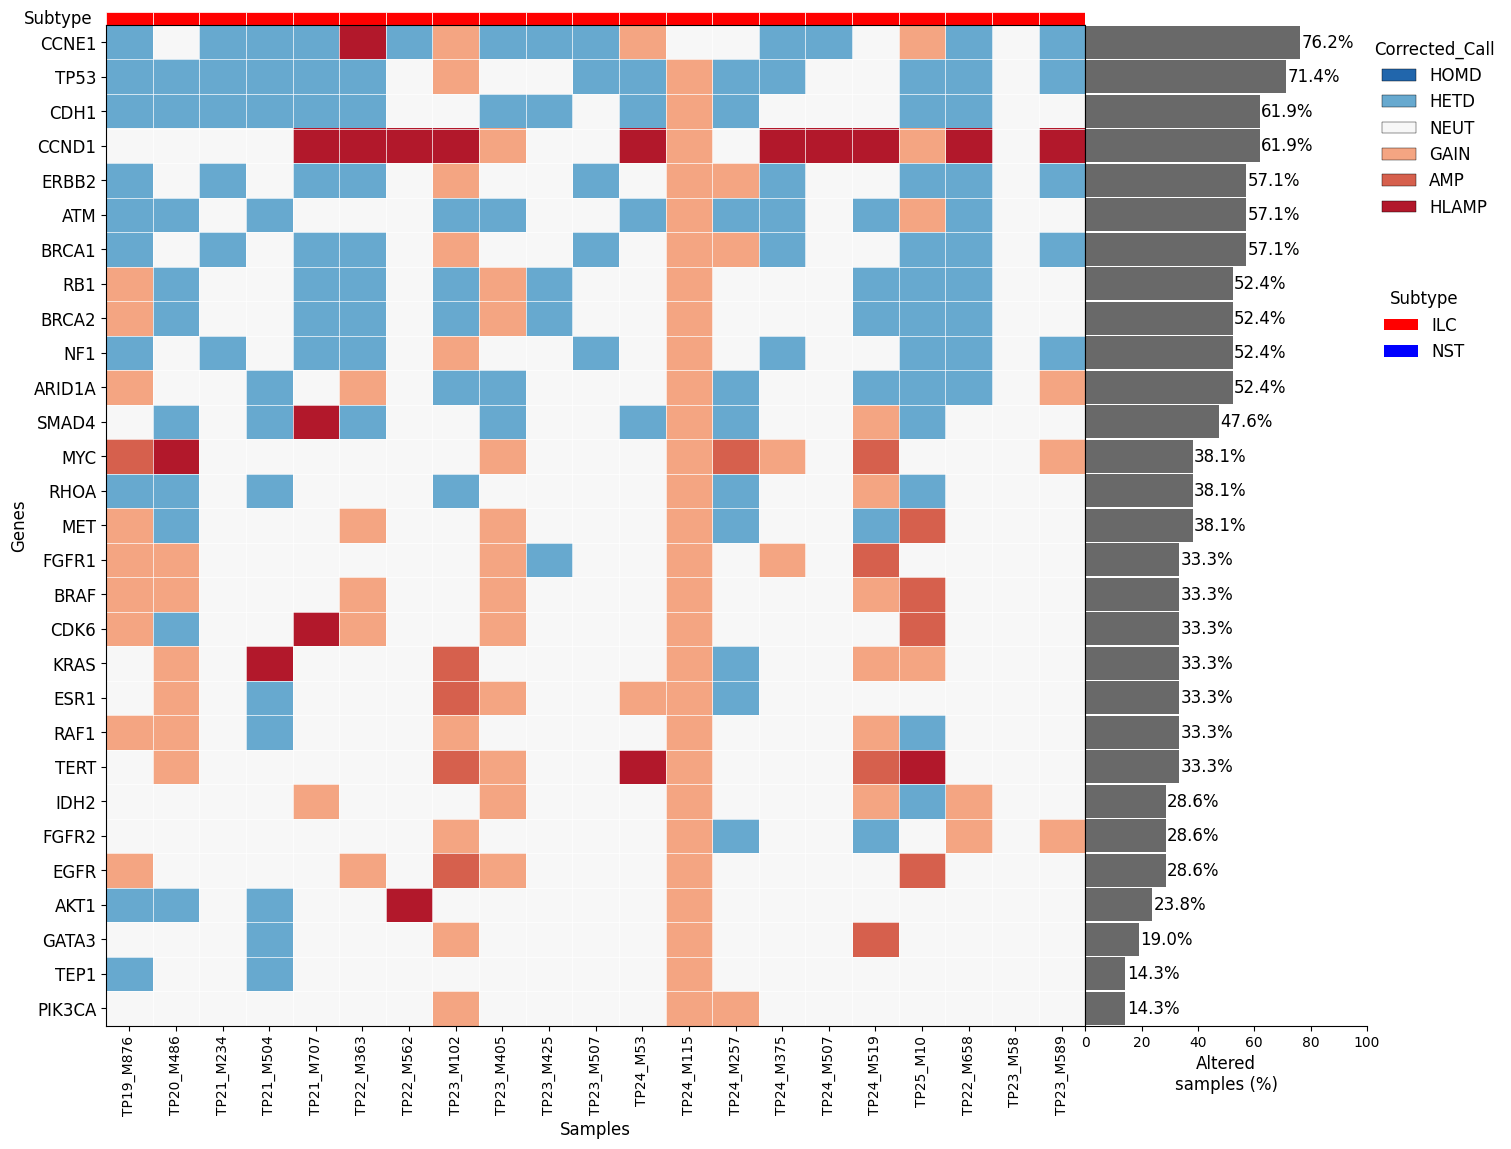

In [66]:
# ============================================================
# Plot categorical Corrected_Call heatmap
# + right barplot = altered sample count per gene
# + genes sorted high -> low by altered count
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.gridspec import GridSpec

# -----------------------------
# Define plotting order and colors
# -----------------------------
CALL_ORDER = ["HOMD", "HETD", "NEUT", "GAIN", "AMP", "HLAMP"]
CALL_TO_NUM = {c: i for i, c in enumerate(CALL_ORDER)}

CALL_COLORS = {
    "HOMD":  "#2166ac",
    "HETD":  "#67a9cf",
    "NEUT":  "#f7f7f7",
    "GAIN":  "#f4a582",
    "AMP":   "#d6604d",
    "HLAMP": "#b2182b",
}

SUBTYPE_COLORS = {
    "ILC": "#FF0000",
    "NST": "#0000FF"
}

# -----------------------------
# Sort genes by altered sample count
# altered = anything except NEUT and not missing
# -----------------------------
altered_count = call_matrix.apply(lambda row: ((row.notna()) & (row != "NEUT")).sum(), axis=1)
altered_count = altered_count.sort_values(ascending=False)

call_matrix_sorted = call_matrix.loc[altered_count.index]
plot_matrix = call_matrix_sorted.replace(CALL_TO_NUM)

print("[INFO] plot_matrix shape:", plot_matrix.shape)

# -----------------------------
# Figure size
# -----------------------------
n_genes = plot_matrix.shape[0]
n_samples = plot_matrix.shape[1]

fig_w = max(14, 0.45 * n_samples + 4)
fig_h = max(8, 0.40 * n_genes)

fig = plt.figure(figsize=(fig_w, fig_h))
gs = GridSpec(
    nrows=2, ncols=2,
    height_ratios=[0.1, 8],
    width_ratios=[8, 2.3],
    hspace=0.00, wspace=0.00
)

ax_top = fig.add_subplot(gs[0, 0])
ax = fig.add_subplot(gs[1, 0])
ax_bar = fig.add_subplot(gs[1, 1], sharey=ax)

# -----------------------------
# Colormap
# -----------------------------
cmap = ListedColormap([CALL_COLORS[c] for c in CALL_ORDER])
norm = BoundaryNorm(np.arange(-0.5, len(CALL_ORDER) + 0.5, 1), cmap.N)

masked_values = np.ma.masked_invalid(plot_matrix.values.astype(float))
cmap = cmap.copy()
cmap.set_bad(color="lightgrey")

im = ax.imshow(masked_values, aspect="auto", cmap=cmap, norm=norm, interpolation="nearest")

# -----------------------------
# Heatmap axis labels
# -----------------------------
ax.set_xticks(np.arange(n_samples))
ax.set_xticklabels(plot_matrix.columns, rotation=90, fontsize=10)

ax.set_yticks(np.arange(n_genes))
ax.set_yticklabels(plot_matrix.index, fontsize=12)

ax.set_xlabel("Samples", fontsize=12)
ax.set_ylabel("Genes", fontsize=12)

# grid lines
ax.set_xticks(np.arange(-0.5, n_samples, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_genes, 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

# -----------------------------
# Top subtype annotation
# -----------------------------
subtype_map = dict(zip(match_df["Sample"], match_df["Subtype"]))

ax_top.set_xlim(-0.5, n_samples - 0.5)
ax_top.set_ylim(0, 1)

for i, sample in enumerate(plot_matrix.columns):
    subtype = subtype_map.get(sample, "Unknown")
    color = SUBTYPE_COLORS.get(subtype, "grey")
    rect = Rectangle((i - 0.5, 0), 1, 1, facecolor=color, edgecolor="white", linewidth=0.5)
    ax_top.add_patch(rect)

ax_top.set_xticks([])
ax_top.set_yticks([])
ax_top.set_frame_on(False)
ax_top.text(-0.8, 0.5, "Subtype", va="center", ha="right", fontsize=12)

# -----------------------------
# Right barplot: altered sample frequency (%)
# altered = anything except NEUT and not missing
# -----------------------------
n_total_samples = call_matrix.shape[1]
altered_freq = (altered_count / n_total_samples) * 100

ypos = np.arange(n_genes)
bar_vals = altered_freq.loc[plot_matrix.index].values

ax_bar.barh(
    ypos,
    bar_vals,
    height=0.95,
    color="dimgray",
    align="center"
)

# match row alignment exactly
ax_bar.set_ylim(ax.get_ylim())
ax_bar.set_xlabel("Altered\nsamples (%)", fontsize=12)
ax_bar.set_yticks(np.arange(n_genes))
ax_bar.tick_params(axis="y", which="both", left=False, right=False, labelleft=False, labelright=False)

# make it visually flush with heatmap
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.spines["left"].set_visible(True)
ax_bar.margins(x=0)

# set x-axis from 0 to 100
ax_bar.set_xlim(0, 100)

# frequency labels
for y, v in enumerate(bar_vals):
    ax_bar.text(v + 0.5, y, f"{v:.1f}%", va="center", ha="left", fontsize=12)
# -----------------------------
# Legends
# -----------------------------
call_handles = [
    Patch(facecolor=CALL_COLORS[c], edgecolor="black", linewidth=0.3, label=c)
    for c in CALL_ORDER
]


subtype_handles = [
    Patch(facecolor=SUBTYPE_COLORS[s], edgecolor="none", label=s)
    for s in ["ILC", "NST"]
]

leg1 = ax.legend(
    handles=call_handles,
    title="Corrected_Call",
    bbox_to_anchor=(1.28, 1.00),
    loc="upper left",
    frameon=False,
    fontsize=12,
    title_fontsize=12
)
ax.add_artist(leg1)

ax.legend(
    handles=subtype_handles,
    title="Subtype",
    bbox_to_anchor=(1.29, 0.75),
    loc="upper left",
    frameon=False,
    fontsize=12,
    title_fontsize=12
)

plt.tight_layout()

# -----------------------------
# Save plot
# -----------------------------
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/EnRich/CNV"
os.makedirs(OUTDIR, exist_ok=True)

png_file = os.path.join(OUTDIR, "selected_gene_CNV_heatmap.png")
pdf_file = os.path.join(OUTDIR, "selected_gene_CNV_heatmap.pdf")

plt.savefig(png_file, dpi=300, bbox_inches="tight")
plt.savefig(pdf_file, bbox_inches="tight")

print("[INFO] Saved PNG:", png_file)
print("[INFO] Saved PDF:", pdf_file)

plt.show()